2023-01-01    11.490142
2023-01-02     9.989248
2023-01-03    12.751146
2023-01-04    15.781211
2023-01-05    10.913701
Freq: D, Name: Nilai_Observasi, dtype: float64
2023-01-01     9.481561
2023-01-02     9.889782
2023-01-03    10.298002
2023-01-04    10.706222
2023-01-05    11.114442
Freq: D, dtype: float64
2023-01-01    2.008581
2023-01-02    0.099466
2023-01-03    2.453145
2023-01-04    5.074989
2023-01-05   -0.200741
Freq: D, Name: Detrended_Series, dtype: float64


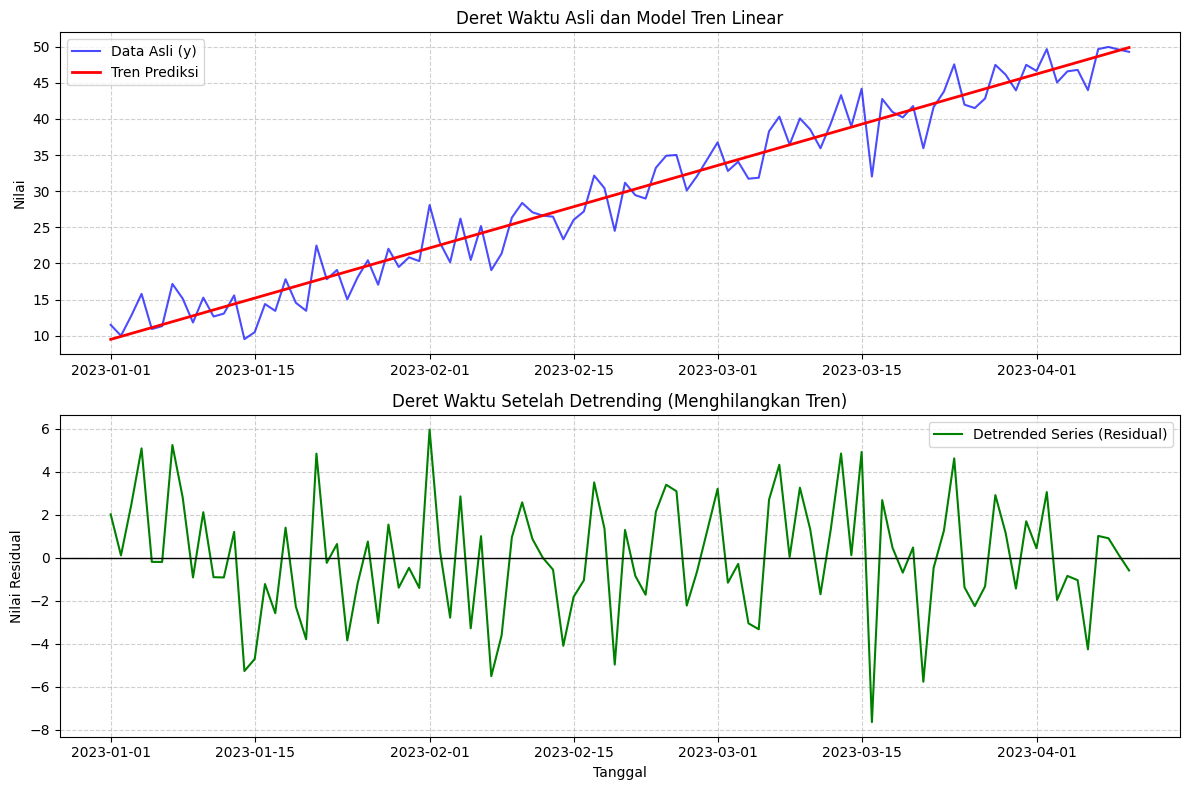

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from statsmodels.tsa.deterministic import DeterministicProcess

dates = pd.date_range("2023-01-01", periods=100, freq="D")

np.random.seed(42)
tren_sebenarnya = np.linspace(10, 50, 100) # Tren naik perlahan dari 10 ke 50
noise = np.random.normal(0, 3, 100)        
y = pd.Series(tren_sebenarnya + noise, index=dates, name="Nilai_Observasi")
print(y.head())

dp = DeterministicProcess(index=y.index, order=1, constant=True)
X_trend = dp.in_sample()

model_trend = LinearRegression()
model_trend.fit(X_trend, y)
y_trend_pred = pd.Series(model_trend.predict(X_trend), index=X_trend.index)
print(y_trend_pred.head())  

y_detrended = y - y_trend_pred
y_detrended.name = "Detrended_Series"
print(y_detrended.head())

plt.figure(figsize=(12, 8))

# Grafik Atas: Data Asli vs Tren yang Ditemukan Model
plt.subplot(2, 1, 1)
plt.plot(y, label='Data Asli (y)', color='blue', alpha=0.7)
plt.plot(y_trend_pred, label='Tren Prediksi', color='red', linewidth=2)
plt.title('Deret Waktu Asli dan Model Tren Linear')
plt.ylabel('Nilai')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

# Grafik Bawah: Hasil Detrending (Sisa / Residual)
plt.subplot(2, 1, 2)
plt.plot(y_detrended, label='Detrended Series (Residual)', color='green')
plt.axhline(0, color='black', linestyle='-', linewidth=1) # Garis nol sebagai referensi
plt.title('Deret Waktu Setelah Detrending (Menghilangkan Tren)')
plt.ylabel('Nilai Residual')
plt.xlabel('Tanggal')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

Tabel Data dengan Fitur Lag:
                   y     lag_1     lag_2
2023-01-01  2.008581       NaN       NaN
2023-01-02  0.099466  2.008581       NaN
2023-01-03  2.453145  0.099466  2.008581
2023-01-04  5.074989  2.453145  0.099466
2023-01-05 -0.200741  5.074989  2.453145
----------------------------------------


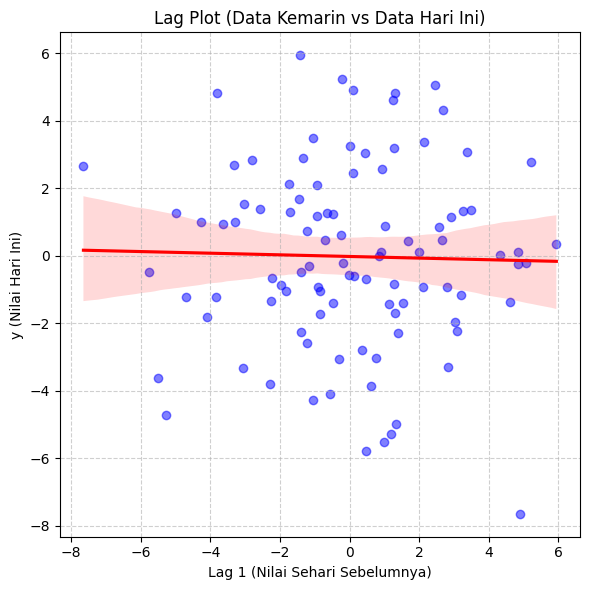

In [ ]:
import seaborn as sns

# Membuat Lag 1 dan Lag 2 menggunakan method shift()
df_lag = pd.DataFrame({
    'y': y_detrended,                # Data hari ini
    'lag_1': y_detrended.shift(1),   # Data kemarin (mundur 1 langkah)
    'lag_2': y_detrended.shift(2)    # Data lusa kemarin (mundur 2 langkah)
})

print("Tabel Data dengan Fitur Lag:")
print(df_lag.head())
print("-" * 40)

plt.figure(figsize=(6, 6))

sns.regplot(
    x='lag_1', 
    y='y', 
    data=df_lag, 
    scatter_kws={'alpha': 0.5, 'color': 'blue'}, 
    line_kws={'color': 'red'}
)

plt.title('Lag Plot (Data Kemarin vs Data Hari Ini)')
plt.xlabel('Lag 1 (Nilai Sehari Sebelumnya)')
plt.ylabel('y (Nilai Hari Ini)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

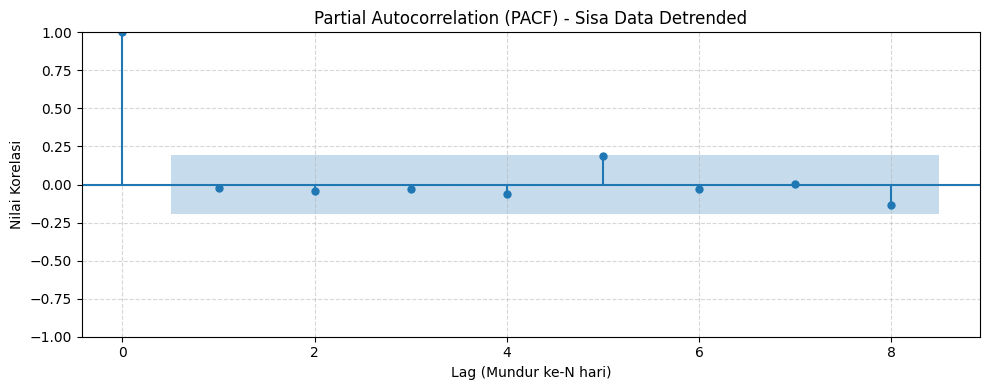

In [ ]:
from statsmodels.graphics.tsaplots import plot_pacf

fig, ax = plt.subplots(figsize=(10, 4))

# Membuat grafik PACF
plot_pacf(y_detrended.dropna(), lags=8, ax=ax)

plt.title("Partial Autocorrelation (PACF) - Sisa Data Detrended")
plt.xlabel("Lag (Mundur ke-N hari)")
plt.ylabel("Nilai Korelasi")
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

            Search_Volume
2023-01-01     524.835708
2023-01-02     493.086785
2023-01-03     532.384427
2023-01-04     576.151493
2023-01-05     488.292331
Tabel Data Siap Model (5 Baris Pertama):
            Penjualan_y  search_lag_1  search_lag_2
2023-01-03   292.424926    493.086785    524.835708
2023-01-04   311.407883    532.384427    493.086785
2023-01-05   344.078039    576.151493    532.384427
2023-01-06   297.015907    488.292331    576.151493
2023-01-07   311.837750    488.293152    488.292331
--------------------------------------------------


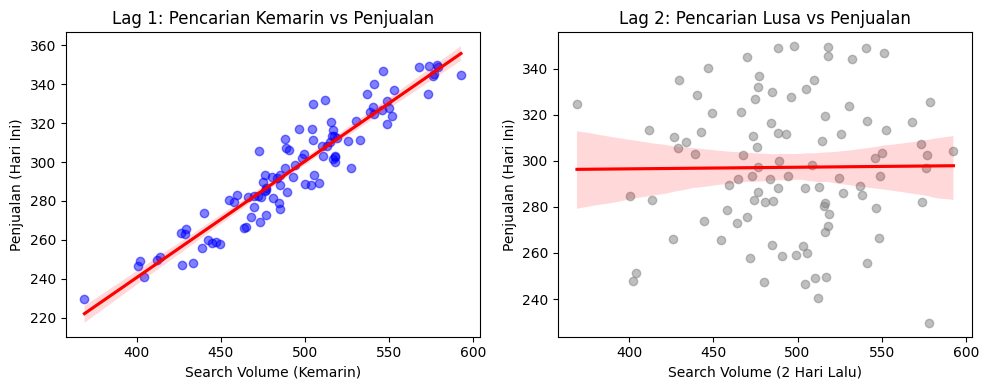

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

dates = pd.date_range("2023-01-01", periods=100, freq="D")
np.random.seed(42)

search_volume = np.random.normal(500, 50, 100) # Rata-rata 500 pencarian/hari
df_external = pd.DataFrame({'Search_Volume': search_volume}, index=dates)
print(df_external.head())

penjualan = (0.6 * df_external['Search_Volume'].shift(1)) + np.random.normal(0, 10, 100)
y = pd.Series(penjualan, index=dates, name="Penjualan_y")

X_leading = pd.DataFrame({
    'search_lag_1': df_external['Search_Volume'].shift(1), # Pencarian Kemarin
    'search_lag_2': df_external['Search_Volume'].shift(2)  # Pencarian Lusa Kemarin
})

df_model = pd.concat([y, X_leading], axis=1)
df_model = df_model.dropna()

print("Tabel Data Siap Model (5 Baris Pertama):")
print(df_model.head())
print("-" * 50)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
sns.regplot(x='search_lag_1', y='Penjualan_y', data=df_model, 
            scatter_kws={'alpha':0.5, 'color':'blue'}, line_kws={'color':'red'})
plt.title('Lag 1: Pencarian Kemarin vs Penjualan')
plt.xlabel('Search Volume (Kemarin)')
plt.ylabel('Penjualan (Hari Ini)')

plt.subplot(1, 2, 2)
sns.regplot(x='search_lag_2', y='Penjualan_y', data=df_model, 
            scatter_kws={'alpha':0.5, 'color':'gray'}, line_kws={'color':'red'})
plt.title('Lag 2: Pencarian Lusa vs Penjualan')
plt.xlabel('Search Volume (2 Hari Lalu)')
plt.ylabel('Penjualan (Hari Ini)')

plt.tight_layout()
plt.show()

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from statsmodels.tsa.deterministic import DeterministicProcess

# Membuat data deret waktu sintetik (100 hari)
np.random.seed(42)
time_index = pd.date_range("2023-01-01", periods=100, freq="D")

# Komponen Target (Kunjungan Pasien) = Tren + Siklus + Noise
trend = np.linspace(10, 50, 100)
cycle = np.sin(np.linspace(0, 20, 100)) * 15
noise = np.random.normal(0, 2, 100)
target_visits = trend + cycle + noise

# Komponen Leading Indicator (Pencarian Google) = Siklus yang terjadi 2 hari lebih awal + Noise
leading_cycle = np.sin(np.linspace(0, 20, 100) + 0.5) * 20 
search_volume = trend + leading_cycle + np.random.normal(0, 3, 100)

df = pd.DataFrame({
    'Visits': target_visits,
    'Search_Volume': search_volume
}, index=time_index)

In [4]:
# Membuat fitur waktu untuk tren linear
dp = DeterministicProcess(index=df.index, order=1, constant=True)
X_time = dp.in_sample()

# Fit target untuk mendapatkan tren
model_trend = LinearRegression()
model_trend.fit(X_time, df['Visits'])
trend_pred = pd.Series(model_trend.predict(X_time), index=df.index)

# Proses Detrending
df['Visits_Detrended'] = df['Visits'] - trend_pred

In [5]:
# Ekstraksi fitur Lag untuk siklus internal
df['Lag_1_Visits'] = df['Visits_Detrended'].shift(1)
df['Lag_2_Visits'] = df['Visits_Detrended'].shift(2)

# Ekstraksi fitur Lag untuk Leading Indicator
df['Lag_1_Search'] = df['Search_Volume'].shift(1)
df['Lag_2_Search'] = df['Search_Volume'].shift(2)

# Membuang baris yang memiliki nilai NaN akibat pergeseran lag
df_model = df.dropna().copy()

In [6]:
# 80 hari pertama untuk training, sisanya untuk testing
train_size = 80
df_train = df_model.iloc[:train_size]
df_test = df_model.iloc[train_size:]

# Menentukan Fitur (X) dan Target (y). Target yang diprediksi adalah data detrended.
fitur = ['Lag_1_Visits', 'Lag_2_Visits', 'Lag_1_Search', 'Lag_2_Search']

X_train = df_train[fitur]
y_train = df_train['Visits_Detrended']

X_test = df_test[fitur]
y_test = df_test['Visits_Detrended']

In [7]:
# Melatih model regresi pada komponen siklus
model_cycle = LinearRegression()
model_cycle.fit(X_train, y_train)

# Melakukan Prediksi
y_pred_cycle = pd.Series(model_cycle.predict(X_test), index=X_test.index)

# REKONSTRUKSI: Mengembalikan prediksi ke skala asli dengan menambahkan kembali nilai tren
y_pred_final = y_pred_cycle + trend_pred.loc[X_test.index]
y_actual_final = df_test['Visits']

Mean Absolute Error (MAE): 2.01
R-Squared (R2): 0.95


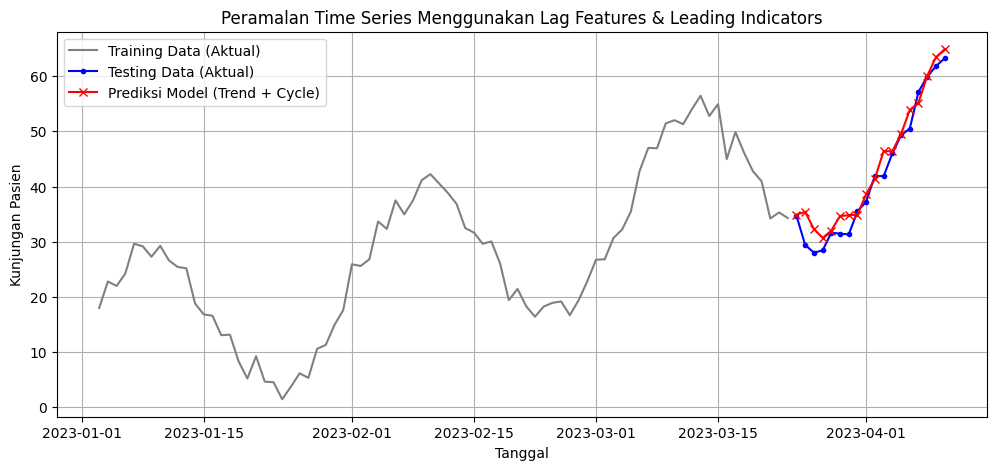

In [8]:
# Menghitung Metrik Evaluasi
mae = mean_absolute_error(y_actual_final, y_pred_final)
r2 = r2_score(y_actual_final, y_pred_final)

print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"R-Squared (R2): {r2:.2f}")

# Visualisasi Prediksi vs Aktual
plt.figure(figsize=(12, 5))
plt.plot(df_train.index, df_train['Visits'], label='Training Data (Aktual)', color='gray')
plt.plot(y_actual_final.index, y_actual_final, label='Testing Data (Aktual)', color='blue', marker='.')
plt.plot(y_pred_final.index, y_pred_final, label='Prediksi Model (Trend + Cycle)', color='red', marker='x')

plt.title("Peramalan Time Series Menggunakan Lag Features & Leading Indicators")
plt.xlabel("Tanggal")
plt.ylabel("Kunjungan Pasien")
plt.legend()
plt.grid(True)
plt.show()

ASSIGNMENT

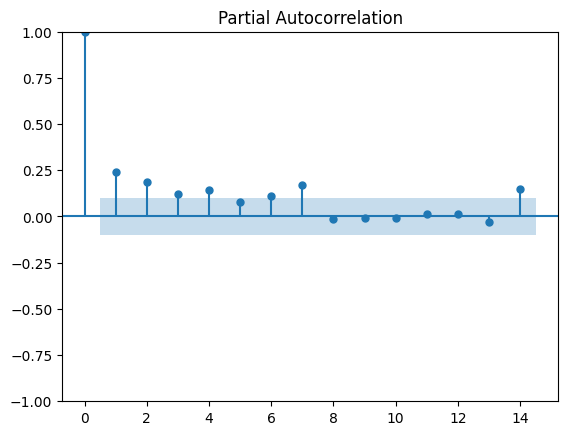

Mean Absolute Error (MAE): 160.92


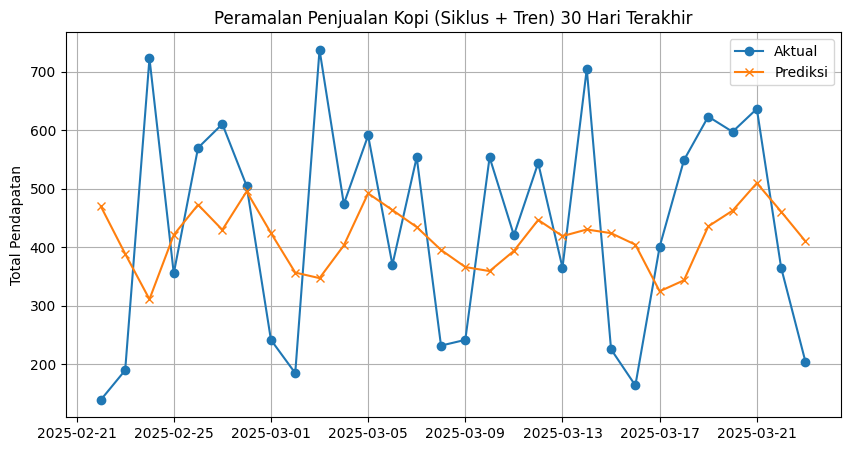

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from statsmodels.tsa.deterministic import DeterministicProcess
from statsmodels.graphics.tsaplots import plot_pacf

# ---------------------------------------------
# Bagian 1: Agregasi
# ---------------------------------------------
df = pd.read_csv('coffee_sales.csv')
df['date'] = pd.to_datetime(df['date'])

# Menghitung total penjualan kopi harian
daily_sales = df.groupby('date')['money'].sum()
daily_sales.index = pd.DatetimeIndex(daily_sales.index).to_period('D')

# ---------------------------------------------
# Bagian 2: Detrending
# ---------------------------------------------
dp = DeterministicProcess(index=daily_sales.index, order=1, constant=True)
X_time = dp.in_sample()

trend_model = LinearRegression()
trend_model.fit(X_time, daily_sales)
trend_pred = pd.Series(trend_model.predict(X_time), index=daily_sales.index)

# Menghasilkan series yang sudah di-detrend
detrended_sales = daily_sales - trend_pred

# ---------------------------------------------
# Bagian 3: PACF
# ---------------------------------------------
# (Opsional) Uncomment untuk menampilkan visualisasi PACF
plot_pacf(detrended_sales.dropna(), lags=14)
plt.show()

# ---------------------------------------------
# Bagian 4: Feature Engineering
# ---------------------------------------------
# Dari hasil PACF yang umumnya menunjukkan korelasi di hari terdekat dan siklus mingguan
df_features = pd.DataFrame({
    'y': detrended_sales,
    'lag_1': detrended_sales.shift(1),
    'lag_2': detrended_sales.shift(2),
    'lag_7': detrended_sales.shift(7)
})

# Buang nilai NaN
df_features.dropna(inplace=True)

# ---------------------------------------------
# Bagian 5: Modeling & Evaluasi
# ---------------------------------------------
# Train/Test split (30 hari terakhir untuk test)
test_days = 30
df_train = df_features.iloc[:-test_days]
df_test = df_features.iloc[-test_days:]

features = ['lag_1', 'lag_2', 'lag_7']
X_train, y_train = df_train[features], df_train['y']
X_test, y_test = df_test[features], df_test['y']

# Melatih model menggunakan lag features
cycle_model = LinearRegression()
cycle_model.fit(X_train, y_train)

# Prediksi siklus pada periode test
cycle_pred = pd.Series(cycle_model.predict(X_test), index=X_test.index)

# Rekonstruksi: Hasil Prediksi Siklus + Hasil Prediksi Tren
final_pred = cycle_pred + trend_pred.loc[X_test.index]
actual_test = daily_sales.loc[X_test.index]

# Hitung Metrik
mae = mean_absolute_error(actual_test, final_pred)
print(f"Mean Absolute Error (MAE): {mae:.2f}")

# Visualisasi
plt.figure(figsize=(10, 5))
plt.plot(actual_test.index.to_timestamp(), actual_test, label='Aktual', marker='o')
plt.plot(final_pred.index.to_timestamp(), final_pred, label='Prediksi', marker='x')
plt.title('Peramalan Penjualan Kopi (Siklus + Tren) 30 Hari Terakhir')
plt.ylabel('Total Pendapatan')
plt.legend()
plt.grid(True)
plt.show()